# Primer modelo de regresión logística para el incumplimiento de plazos

**Evaluación Formativa 2 · MCDI501 Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial · Universidad Andrés Bello

| | |
|---|---|
| **Grupo** | 6 |
| **Integrantes** | Marco Álvarez Araya · Ricardo Jaramillo |
| **Docente** | Dr. Jean Paul Maidana González |
| **Fecha** | 25-10-2026 |
| **Dataset** | E-Commerce Shipping Data (Prachi13, Kaggle): 10.999 envíos, 12 variables |
| **Repositorio** | https://github.com/RJaramilloP/mcdi501-ecommerce-grupo6 |

## Propósito

Esta formativa ensaya el flujo completo de modelamiento que la Sumativa 3 (S3) amplía: preparar los datos a partir de lo que encontraron la Sumativa 1 (S1) y la Sumativa 2 (S2), ajustar **un** modelo de regresión logística, diagnosticarlo y evaluar su desempeño predictivo en datos no usados para ajustarlo.

**Punto de partida.** S1 detectó que el bloque inicial del archivo (ID ≤ 3.135) tiene un 100 % de envíos fuera de plazo y concentra los descuentos mayores a 10. S2 mostró que casi todas las asociaciones de S1 dependen de ese bloque: en el subconjunto ID > 3.135 la correlación del descuento cae de 0,335 a −0,010 y solo la importancia alta del producto conserva su dirección y una magnitud similar (+5,81 pp en el completo, +4,31 pp en ID > 3.135). Por eso, siguiendo la indicación del docente para S3, el modelo se ajusta **dentro de ID > 3.135**.

| Parte | Pregunta | Insumos |
|---|---|---|
| 1. Preparación | ¿Con qué datos, faltantes y partición se modela? | S1 (Tablas 1, 3, 5, 8 y 9) · S2 (reporte de resultados validados, bootstrap por bloques) |
| 2. Modelo | ¿Qué variables entran y qué dicen sus odds ratios? | S1 (Tablas 5, 6 y 15) · S2 (Tabla 3 y estados de validación) |
| 3. Desempeño | ¿El modelo discrimina mejor que el azar en el conjunto de prueba? | Matriz de confusión, métricas, ROC, AUC con IC bootstrap y prueba de permutación |
| 4. Síntesis | ¿Qué se lleva a S3? | Todo lo anterior |

**Faltantes inducidos.** La base no tiene valores faltantes (S1, sección 1.1). Siguiendo las instrucciones del curso, se eliminan de forma **completamente aleatoria (MCAR)** el 12 % de los valores de dos variables numéricas, con semilla fija. La rutina se ejecuta **una sola vez**: la máscara se guarda en `datos/derivados/mascara_mcar.csv` y S3 la reutiliza tal cual.

**Reproducibilidad.** Semilla 42, huella SHA-256 del CSV, partición e imputación ajustadas solo con el conjunto de entrenamiento, y todas las tablas y figuras exportadas a `F2/resultados/`.

## 0. Entorno y datos

### 0.1 Librerías, semilla y constantes

In [1]:
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from IPython.display import display, Markdown

SEED = 42                      # semilla única del proyecto (S1, S2 y F2)
CORTE_ID = 3135                # corte del bloque inicial definido en S1 (sección 2.6)
OBJETIVO = "Reached.on.Time_Y.N"   # 1 = fuera de plazo
VARS_FALTANTES = ["Cost_of_the_Product", "Weight_in_gms"]
PROP_FALTANTES = 0.12          # 12 % MCAR por variable (rango indicado por el curso: 10 %-15 %)
PROP_PRUEBA = 0.30             # partición 70/30
B_BOOT = 10_000                # remuestras bootstrap del AUC
B_PERM = 10_000                # permutaciones del AUC
SHA_ESPERADO = "dcdc3fd8f0507ec400174ef70d88d634321cc2ce8f4ea11bf4e8c847fdd325b3"
assert min(B_BOOT, B_PERM) >= 10_000

C_A_TIEMPO, C_FUERA = "#2A74B0", "#BC5A45"
C_GRIS = "#7F7F7F"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 8, "axes.titlesize": 8.5,
    "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "lines.linewidth": 1.2, "axes.linewidth": 0.7, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9A9A9A", "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Rutas: el notebook vive en F2/notebooks/; la raíz contiene S1/, S2/, F2/ y datos/.
RAIZ = Path.cwd()
while not ((RAIZ / "S1").is_dir() and (RAIZ / "datos").is_dir()):
    if RAIZ.parent == RAIZ:
        raise FileNotFoundError("No se encontró la raíz del repositorio (carpetas S1/ y datos/)")
    RAIZ = RAIZ.parent
S1_TABLAS = RAIZ / "S1" / "resultados" / "tablas"
S2_TABLAS = RAIZ / "S2" / "resultados" / "tablas"
DIR_DERIVADOS = RAIZ / "datos" / "derivados"
DIR_TABLAS = RAIZ / "F2" / "resultados" / "tablas"
DIR_FIGURAS = RAIZ / "F2" / "resultados" / "figuras"
for d in (DIR_DERIVADOS, DIR_TABLAS, DIR_FIGURAS):
    d.mkdir(parents=True, exist_ok=True)


def guardar_tabla(tabla, nombre, index=False):
    # Exporta la tabla a F2/resultados/tablas/<nombre>.csv y la devuelve para mostrarla.
    tabla.to_csv(DIR_TABLAS / f"{nombre}.csv", index=index, encoding="utf-8")
    return tabla


def es(x, d=2):
    # Número con la convención del informe: 3.634,02 y signo menos tipográfico.
    t = f"{x:,.{d}f}"
    return t.replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")


def pct(x, d=1):
    return es(100 * x, d) + " %"


def _marca_es(v, pos=None):
    t = f"{v:,.10g}"
    return t.replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")


def guardar_figura(fig, nombre):
    # Exporta la figura a F2/resultados/figuras/<nombre>.png con decimales en coma.
    for ax in fig.axes:
        for eje in (ax.xaxis, ax.yaxis):
            if eje.get_scale() == "linear" and type(eje.get_major_formatter()) is matplotlib.ticker.ScalarFormatter:
                eje.set_major_formatter(matplotlib.ticker.FuncFormatter(_marca_es))
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", bbox_inches="tight", facecolor="white")


def s1(nombre, **kw):
    return pd.read_csv(S1_TABLAS / f"{nombre}.csv", **kw)


def s2(nombre, **kw):
    return pd.read_csv(S2_TABLAS / f"{nombre}.csv", **kw)


print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · "
      f"scipy {scipy.__version__} · statsmodels {statsmodels.__version__} · scikit-learn {sklearn.__version__} · "
      f"matplotlib {matplotlib.__version__}")
print(f"Semilla = {SEED} · faltantes MCAR = {PROP_FALTANTES:.0%} en {', '.join(VARS_FALTANTES)} · "
      f"partición {1 - PROP_PRUEBA:.0%}/{PROP_PRUEBA:.0%} · B_BOOT = {B_BOOT:,} · B_PERM = {B_PERM:,}")

Python 3.13.16 · numpy 2.5.3 · pandas 3.0.5 · scipy 1.18.1 · statsmodels 0.15.0 · scikit-learn 1.9.1 · matplotlib 3.11.2
Semilla = 42 · faltantes MCAR = 12% en Cost_of_the_Product, Weight_in_gms · partición 70%/30% · B_BOOT = 10,000 · B_PERM = 10,000


### 0.2 Carga del CSV original y control de versión

Se verifica la huella SHA-256 para analizar exactamente el mismo archivo que en S1 y S2, y se comprueban las dos propiedades del archivo en que se apoya todo el proyecto: no tiene faltantes y el bloque ID ≤ 3.135 está 100 % fuera de plazo.

In [2]:
ruta_csv = RAIZ / "datos" / "originales" / "ecommerce-shipping.csv"
if not ruta_csv.is_file():
    raise FileNotFoundError(f"Falta el CSV original en {ruta_csv} (ver README, sección Datos)")
sha = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
assert sha == SHA_ESPERADO, "El CSV no coincide con la versión analizada en S1 y S2"

df_original = pd.read_csv(ruta_csv)
assert df_original.shape == (10_999, 12)
assert int(df_original.isna().sum().sum()) == 0, "S1 documentó 0 faltantes"
assert df_original.loc[df_original["ID"] <= CORTE_ID, OBJETIVO].eq(1).all()

print(f"SHA-256 verificado · {len(df_original):,} envíos · {df_original.shape[1]} variables · 0 faltantes")
print(f"ID ≤ {CORTE_ID:,}: {int((df_original['ID'] <= CORTE_ID).sum()):,} envíos, 100 % fuera de plazo")
print(f"ID > {CORTE_ID:,}: {int((df_original['ID'] > CORTE_ID).sum()):,} envíos, "
      f"{df_original.loc[df_original['ID'] > CORTE_ID, OBJETIVO].mean():.2%} fuera de plazo")

SHA-256 verificado · 10,999 envíos · 12 variables · 0 faltantes
ID ≤ 3,135: 3,135 envíos, 100 % fuera de plazo
ID > 3,135: 7,864 envíos, 43.59% fuera de plazo


## 1. Preparación de datos para modelamiento

### 1.1 Hallazgos de la Sumativa 1

No se repite el análisis de S1: se leen sus tablas exportadas y se verifica que coincidan con el recálculo. La tabla resume los cuatro hallazgos que condicionan el modelamiento: correlaciones con el objetivo, faltantes, valores atípicos y el bloque inicial.

In [3]:
t05 = s1("tab05_correlacion_objetivo", index_col=0)
t09 = s1("tab09_reglas_frontera")
t08 = s1("tab08_comparacion_bloques", index_col=0)
dicc = s1("diccionario_variables")

# Control: la correlación de Spearman de S1 coincide con el recálculo sobre el CSV.
for v in t05.index:
    rho = stats.spearmanr(df_original[v], df_original[OBJETIVO]).statistic
    assert np.isclose(rho, t05.loc[v, "spearman"], atol=1e-12), v
assert int(dicc["faltantes"].sum()) == 0

# Valores atípicos por la regla del rango intercuartílico (misma regla de S1).
def n_atipicos(x):
    q1, q3 = np.percentile(x, [25, 75])
    return int(((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum())

atip = {v: n_atipicos(df_original[v]) for v in ["Cost_of_the_Product", "Weight_in_gms", "Discount_offered",
                                                  "Prior_purchases", "Customer_care_calls"]}
nombres = {"Discount_offered": "Descuento", "Weight_in_gms": "Peso", "Prior_purchases": "Compras previas",
           "Cost_of_the_Product": "Costo", "Customer_care_calls": "Llamadas", "Customer_rating": "Calificación"}
corr_txt = "; ".join(f"{nombres[v]} {es(t05.loc[v, 'spearman'], 3)}" for v in t05.index)
f_desc = t09.set_index("condicion").loc["Descuento > 10"]

hallazgos_s1 = guardar_tabla(pd.DataFrame([
    {"hallazgo": "Correlaciones de Spearman con el retraso (Tabla 5)", "valor_s1": corr_txt,
     "implicancia_f2": "Candidatas iniciales; se contrastan con su validación en S2 antes de usarlas."},
    {"hallazgo": "Valores faltantes (Tabla 1, diccionario)", "valor_s1": "0 en las 12 variables",
     "implicancia_f2": "Se inducen faltantes MCAR controlados para ensayar su tratamiento (sección 1.3)."},
    {"hallazgo": "Valores atípicos (regla IQR)",
     "valor_s1": f"Descuento {es(atip['Discount_offered'], 0)}; compras previas {es(atip['Prior_purchases'], 0)}; costo, peso y llamadas 0",
     "implicancia_f2": "S1 los conservó por no ser errores; en ID > 3.135 el descuento máximo es 10 y no tiene atípicos."},
    {"hallazgo": "Bloque inicial ID ≤ 3.135 (Tablas 8 y 9)",
     "valor_s1": f"100 % fuera de plazo; descuento > 10 en {es(f_desc['n'], 0)} envíos, todos fuera de plazo",
     "implicancia_f2": "Separación casi perfecta en el completo: el modelo se ajusta en ID > 3.135."},
]), "f2_tab01_hallazgos_s1")
display(hallazgos_s1)

,hallazgo,valor_s1,implicancia_f2
0,Correlaciones de Spearman con el retraso (Tabl...,"Descuento 0,335; Peso −0,266; Compras previas ...",Candidatas iniciales; se contrastan con su val...
1,"Valores faltantes (Tabla 1, diccionario)",0 en las 12 variables,Se inducen faltantes MCAR controlados para ens...
2,Valores atípicos (regla IQR),"Descuento 2.209; compras previas 1.003; costo,...",S1 los conservó por no ser errores; en ID > 3....
3,Bloque inicial ID ≤ 3.135 (Tablas 8 y 9),100 % fuera de plazo; descuento > 10 en 2.647 ...,Separación casi perfecta en el completo: el mo...


### 1.2 Hallazgos de la Sumativa 2

S2 entregó un reporte de resultados validados con una regla única de clasificación: **robusto** (coherente entre métodos y estable entre conjuntos), **señal exploratoria** (misma dirección en ambos conjuntos, pero sin confirmación tras corregir por multiplicidad) y **dependiente del bloque**. Se leen el reporte, los IC bootstrap de las correlaciones en ID > 3.135 y el diagnóstico de dependencia por orden del bootstrap por bloques.

In [4]:
validados = pd.read_csv(RAIZ / "S2" / "resultados_validados.csv")
t03 = s2("s2_tab03_correlaciones_bootstrap")
t05b = s2("s2_tab05b_bootstrap_bloques")
t02 = s2("s2_tab02_permutacion")

print("Estados del reporte de S2:", validados["estado"].value_counts().to_dict())
display(validados.loc[validados["estado"].ne("Dependiente del bloque"), ["resultado_s1", "estado", "implicancia_s3"]])

corr_sub = t03.loc[t03["conjunto"].eq("ID > 3.135"), ["variable", "rho", "ic_inf", "ic_sup", "estado"]]
display(corr_sub)
razon_sub = t05b.loc[t05b["conjunto"].eq("ID > 3.135"), "razon_ee_proporcion"]
z_sub = t02.loc[t02["conjunto"].eq("ID > 3.135") & t02["prueba"].str.startswith("Alta")].iloc[0]
print(f"Bootstrap por bloques en ID > 3.135: razón de EE de la proporción entre {razon_sub.min():.2f} y {razon_sub.max():.2f}")
print(f"Importancia alta vs. resto en ID > 3.135: p permutación = {z_sub['p_perm_final']:.4f}, Holm = {z_sub['p_holm_subconjunto']:.3f}")

Estados del reporte de S2: {'Dependiente del bloque': 13, 'Señal exploratoria': 2, 'Robusto': 1}


,resultado_s1,estado,implicancia_s3
1,Costo medio,Robusto,Usable como descriptor en ambos conjuntos.
8,Prueba 2: importancia × cumplimiento (χ²),Señal exploratoria,"Asociación muy débil (V ≈ 0,03); no tratarla c..."
9,Contraste importancia alta vs. resto (z),Señal exploratoria,"Candidata a predictor en S3, sin interpretarla..."


,variable,rho,ic_inf,ic_sup,estado
5,Descuento,-0.010241,-0.032211,0.012151,Dependiente del bloque
6,Peso,-0.022748,-0.045103,-0.000312,Atenuada
7,Compras previas,0.007284,-0.015081,0.029659,Dependiente del bloque
8,Costo,0.034342,0.011634,0.055989,Invierte el signo
9,Llamadas,0.026223,0.004226,0.047648,Invierte el signo


Bootstrap por bloques en ID > 3.135: razón de EE de la proporción entre 0.92 y 1.01
Importancia alta vs. resto en ID > 3.135: p permutación = 0.0357, Holm = 0.143


In [5]:
fila = lambda clave: validados.loc[validados["resultado_s1"].str.startswith(clave)].iloc[0]
rho_s = corr_sub.set_index("variable")
hallazgos_s2 = guardar_tabla(pd.DataFrame([
    {"hallazgo_s2": "Parámetros robustos", "evidencia": f"Solo el costo medio ({fila('Costo medio')['estado'].lower()}); "
     "proporción, peso y descuento dependen del bloque",
     "decision_f2": "El costo entra como predictor numérico; el peso se resume por su mediana (bimodal)."},
    {"hallazgo_s2": "Correlaciones estables", "evidencia": "Ninguna: las 5 cambian, se atenúan o invierten su signo en ID > 3.135",
     "decision_f2": "Las variables se eligen por su evidencia dentro de ID > 3.135, no por la del conjunto completo."},
    {"hallazgo_s2": "Señal exploratoria", "evidencia": f"Importancia alta vs. resto: p = {es(z_sub['p_perm_final'], 4)}, Holm {es(z_sub['p_holm_subconjunto'], 3)}",
     "decision_f2": "Predictor principal del modelo, interpretado como exploratorio."},
    {"hallazgo_s2": "ρ de Spearman en ID > 3.135", "evidencia":
     f"Costo {es(rho_s.loc['Costo', 'rho'], 3)} [{es(rho_s.loc['Costo', 'ic_inf'], 3)}; {es(rho_s.loc['Costo', 'ic_sup'], 3)}]; "
     f"peso {es(rho_s.loc['Peso', 'rho'], 3)} [{es(rho_s.loc['Peso', 'ic_inf'], 3)}; {es(rho_s.loc['Peso', 'ic_sup'], 4)}]; "
     f"descuento {es(rho_s.loc['Descuento', 'rho'], 3)} [{es(rho_s.loc['Descuento', 'ic_inf'], 3)}; {es(rho_s.loc['Descuento', 'ic_sup'], 3)}]",
     "decision_f2": "Costo y peso excluyen el 0; el descuento no: se excluye."},
    {"hallazgo_s2": "Dependencia según el orden del archivo",
     "evidencia": f"Razón de EE con bloques de 50 a 500 envíos: {es(razon_sub.min(), 2)}-{es(razon_sub.max(), 2)} en ID > 3.135 (11,3 en el completo)",
     "decision_f2": "En ID > 3.135 no hay estructura por orden: una partición aleatoria estratificada es válida."},
    {"hallazgo_s2": "Fuga de información (recomendación 3)", "evidencia": "Momento de registro de llamadas y calificación desconocido (S1, Tabla 1)",
     "decision_f2": "Llamadas y calificación quedan fuera del modelo predictivo."},
]), "f2_tab02_hallazgos_s2")
display(hallazgos_s2)

,hallazgo_s2,evidencia,decision_f2
0,Parámetros robustos,"Solo el costo medio (robusto); proporción, pes...",El costo entra como predictor numérico; el pes...
1,Correlaciones estables,"Ninguna: las 5 cambian, se atenúan o invierten...",Las variables se eligen por su evidencia dentr...
2,Señal exploratoria,"Importancia alta vs. resto: p = 0,0357, Holm 0...","Predictor principal del modelo, interpretado c..."
3,ρ de Spearman en ID > 3.135,"Costo 0,034 [0,012; 0,056]; peso −0,023 [−0,04...",Costo y peso excluyen el 0; el descuento no: s...
4,Dependencia según el orden del archivo,"Razón de EE con bloques de 50 a 500 envíos: 0,...",En ID > 3.135 no hay estructura por orden: una...
5,Fuga de información (recomendación 3),Momento de registro de llamadas y calificación...,Llamadas y calificación quedan fuera del model...


### 1.3 Faltantes inducidos de forma controlada (MCAR)

**Diseño.** Se eligen dos variables numéricas relevantes para el modelo: el **costo**, el único parámetro robusto de S2, y el **peso**, cuya imputación S2 advirtió que no debe suponer normalidad por su distribución bimodal. En cada una se eliminan 1.320 valores (12 %) elegidos al azar sobre el archivo completo de 10.999 envíos: cada valor tiene la misma probabilidad de ser eliminado, independiente de su magnitud y del resto de las variables. Ese es, por construcción, el mecanismo MCAR.

**Una sola vez.** La primera ejecución guarda la máscara (ID y variable de cada valor eliminado, sin los valores) en `datos/derivados/mascara_mcar.csv`. Las ejecuciones posteriores, y S3, la regeneran y verifican que sea idéntica. Los valores originales siguen disponibles en el CSV original, lo que en S3 permitirá medir el error de imputación contra el valor verdadero.

In [6]:
rng = np.random.default_rng(SEED)
n_total = len(df_original)
k_faltantes = round(PROP_FALTANTES * n_total)
filas = []
for v in VARS_FALTANTES:
    pos = rng.choice(n_total, size=k_faltantes, replace=False)    # muestreo sin reemplazo, equiprobable
    filas += [{"variable": v, "ID": int(i)} for i in df_original["ID"].to_numpy()[pos]]
mascara = pd.DataFrame(filas).sort_values(["variable", "ID"], ignore_index=True)

ruta_mascara = DIR_DERIVADOS / "mascara_mcar.csv"
if ruta_mascara.is_file():
    guardada = pd.read_csv(ruta_mascara)
    assert guardada.equals(mascara), "La máscara guardada no coincide con la rutina: no se debe regenerar"
    print("Máscara existente verificada: idéntica a la rutina con semilla 42.")
else:
    mascara.to_csv(ruta_mascara, index=False)
    print("Máscara creada y guardada (primera ejecución).")

# Dataset con faltantes: copia del original con los valores enmascarados.
df = df_original.copy()
for v in VARS_FALTANTES:
    df.loc[df["ID"].isin(mascara.loc[mascara["variable"].eq(v), "ID"]), v] = np.nan

ambos = df[VARS_FALTANTES].isna().all(axis=1).sum()
alguno = df[VARS_FALTANTES].isna().any(axis=1).sum()
print(f"{k_faltantes:,} faltantes por variable · {ambos:,} envíos sin ambos valores · {alguno:,} envíos con al menos un faltante")

Máscara existente verificada: idéntica a la rutina con semilla 42.
1,320 faltantes por variable · 163 envíos sin ambos valores · 2,477 envíos con al menos un faltante


**Verificación del mecanismo.** Si los faltantes son MCAR, los envíos con y sin el valor eliminado no deben diferir en ninguna otra variable, incluido el objetivo. Se contrasta con Welch para las variables numéricas y χ² para las categóricas, y se corrige por Holm porque son muchas pruebas. Esto verifica la implementación de la rutina, no un supuesto: el mecanismo es MCAR por diseño.

In [7]:
otras_num = ["Customer_care_calls", "Customer_rating", "Prior_purchases", "Discount_offered"]
otras_cat = ["Warehouse_block", "Mode_of_Shipment", "Product_importance", "Gender", OBJETIVO]
filas = []
for v in VARS_FALTANTES:
    falta = df[v].isna()
    for w in otras_num + [u for u in VARS_FALTANTES if u != v]:
        a, b = df_original.loc[falta, w], df_original.loc[~falta, w]
        filas.append({"variable_con_faltantes": v, "comparada": w, "prueba": "Welch",
                      "media_faltante": a.mean(), "media_observado": b.mean(),
                      "p": stats.ttest_ind(a, b, equal_var=False).pvalue})
    for w in otras_cat:
        tabla = pd.crosstab(falta, df_original[w])
        filas.append({"variable_con_faltantes": v, "comparada": w, "prueba": "χ²",
                      "media_faltante": np.nan, "media_observado": np.nan,
                      "p": stats.chi2_contingency(tabla).pvalue})
control_mcar = pd.DataFrame(filas)
control_mcar["p_holm"] = multipletests(control_mcar["p"], method="holm")[1]
guardar_tabla(control_mcar, "f2_tab03_control_mcar")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(control_mcar)
print(f"{len(control_mcar)} contrastes · mínimo p = {control_mcar['p'].min():.4f} · mínimo p Holm = {control_mcar['p_holm'].min():.3f}")
assert control_mcar["p_holm"].min() > 0.05, "La rutina debería producir faltantes sin asociación (MCAR)"

,variable_con_faltantes,comparada,prueba,media_faltante,media_observado,p,p_holm
0,Cost_of_the_Product,Customer_care_calls,Welch,4.0545,4.0544,0.9977,1.0000
1,Cost_of_the_Product,Customer_rating,Welch,3.0038,2.9887,0.7169,1.0000
2,Cost_of_the_Product,Prior_purchases,Welch,3.6432,3.5573,0.0646,1.0000
3,Cost_of_the_Product,Discount_offered,Welch,12.8318,13.4471,0.1841,1.0000
4,Cost_of_the_Product,Weight_in_gms,Welch,3641.6386,3632.9773,0.8566,1.0000
5,Cost_of_the_Product,Warehouse_block,χ²,NaN,NaN,0.9442,1.0000
6,Cost_of_the_Product,Mode_of_Shipment,χ²,NaN,NaN,0.5842,1.0000
7,Cost_of_the_Product,Product_importance,χ²,NaN,NaN,0.9622,1.0000
8,Cost_of_the_Product,Gender,χ²,NaN,NaN,0.2658,1.0000
9,Cost_of_the_Product,Reached.on.Time_Y.N,χ²,NaN,NaN,0.8638,1.0000


20 contrastes · mínimo p = 0.0611 · mínimo p Holm = 1.000


### 1.4 Subconjunto de modelamiento y partición 70/30

El modelo se ajusta en ID > 3.135 (7.864 envíos, 43,6 % fuera de plazo): es el régimen donde S2 mostró que las asociaciones no están dominadas por el bloque inicial y donde el descuento ya no separa las clases. La partición es **aleatoria y estratificada por el objetivo**, para que entrenamiento y prueba conserven la misma tasa de retraso. Una partición aleatoria es válida aquí porque el bootstrap por bloques de S2 no encontró estructura según el orden del archivo dentro de ID > 3.135 (sección 1.2); en el conjunto completo, en cambio, el error estándar crecía 11,3 veces y habría exigido una partición por bloques.

Los ID de cada conjunto se guardan en `datos/derivados/particion_70_30.csv` para que S3 use exactamente la misma partición.

In [8]:
sub = df.loc[df["ID"] > CORTE_ID].copy()
sub["Importancia_alta"] = sub["Product_importance"].eq("high").astype(int)
entrenamiento, prueba = train_test_split(sub, test_size=PROP_PRUEBA, stratify=sub[OBJETIVO], random_state=SEED)
entrenamiento, prueba = entrenamiento.copy(), prueba.copy()

particion = pd.concat([pd.DataFrame({"ID": entrenamiento["ID"], "conjunto": "entrenamiento"}),
                       pd.DataFrame({"ID": prueba["ID"], "conjunto": "prueba"})]).sort_values("ID", ignore_index=True)
ruta_particion = DIR_DERIVADOS / "particion_70_30.csv"
if ruta_particion.is_file():
    assert pd.read_csv(ruta_particion).equals(particion), "La partición guardada no coincide"
else:
    particion.to_csv(ruta_particion, index=False)

resumen_particion = guardar_tabla(pd.DataFrame([
    {"conjunto": nombre, "n": len(d), "fuera_de_plazo": int(d[OBJETIVO].sum()), "tasa_fuera_plazo": d[OBJETIVO].mean(),
     "faltantes_costo": int(d["Cost_of_the_Product"].isna().sum()), "faltantes_peso": int(d["Weight_in_gms"].isna().sum()),
     "filas_completas": int(d[VARS_FALTANTES].notna().all(axis=1).sum())}
    for nombre, d in [("ID > 3.135", sub), ("Entrenamiento", entrenamiento), ("Prueba", prueba)]
]), "f2_tab04_particion")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(resumen_particion)
assert abs(entrenamiento[OBJETIVO].mean() - prueba[OBJETIVO].mean()) < 0.001

,conjunto,n,fuera_de_plazo,tasa_fuera_plazo,faltantes_costo,faltantes_peso,filas_completas
0,ID > 3.135,7864,3428,0.4359,959,936,6085
1,Entrenamiento,5504,2399,0.4359,641,647,4291
2,Prueba,2360,1029,0.4360,318,289,1794


### 1.5 Tratamiento de los faltantes: imputación por la mediana

**Por qué la mediana.** Con faltantes MCAR, eliminar las filas incompletas no sesga las estimaciones, pero aquí descarta un 22 % de los envíos de entrenamiento, y S2 mostró que la potencia ya es baja: con n = 7.864, la probabilidad de detectar una diferencia de 4 pp entre importancia alta y el resto es de 49 %. La mediana conserva todos los envíos, es robusta a la asimetría y es el resumen que S2 recomendó para el peso, cuya distribución es bimodal y cuya media cae entre las dos modas, en una zona con pocos envíos.

**Sin fuga de información.** La mediana se calcula **solo con el conjunto de entrenamiento** y se aplica a ambos conjuntos, como ocurriría con envíos nuevos. Se cuantifica su costo: la imputación concentra el 12 % de los valores en un único punto y reduce la dispersión de la variable. Como se conocen los valores verdaderos, se informa además el error de imputación; S3 lo comparará con la imputación por regresión.

In [9]:
medianas = entrenamiento[VARS_FALTANTES].median()
originales = df_original.set_index("ID")
filas = []
for v in VARS_FALTANTES:
    for nombre, d in [("Entrenamiento", entrenamiento), ("Prueba", prueba)]:
        falta = d[v].isna()
        verdadero = originales.loc[d.loc[falta, "ID"], v].to_numpy()
        imputado = d[v].fillna(medianas[v])
        filas.append({"variable": v, "conjunto": nombre, "mediana_entrenamiento": medianas[v],
                      "imputados": int(falta.sum()),
                      "de_observado": d[v].std(), "de_tras_imputar": imputado.std(),
                      "cambio_de_pct": 100 * (imputado.std() / d[v].std() - 1),
                      "rmse_vs_verdadero": float(np.sqrt(np.mean((verdadero - medianas[v]) ** 2))),
                      "sesgo_vs_verdadero": float(np.mean(medianas[v] - verdadero))})
        d[v + "_faltante"] = falta.astype(int)
        d[v] = imputado
imputacion = guardar_tabla(pd.DataFrame(filas), "f2_tab05_imputacion_mediana")
with pd.option_context("display.float_format", "{:.2f}".format):
    display(imputacion)
assert entrenamiento[VARS_FALTANTES].notna().all().all() and prueba[VARS_FALTANTES].notna().all().all()
n_completas = int(resumen_particion.loc[1, "filas_completas"])
print(f"Eliminación de casos dejaría {n_completas:,} de {len(entrenamiento):,} envíos de entrenamiento "
      f"({1 - n_completas / len(entrenamiento):.1%} menos).")

,variable,conjunto,mediana_entrenamiento,imputados,de_observado,de_tras_imputar,cambio_de_pct,rmse_vs_verdadero,sesgo_vs_verdadero
0,Cost_of_the_Product,Entrenamiento,223.00,641,48.08,45.26,-5.86,48.29,5.45
1,Cost_of_the_Product,Prueba,223.00,318,47.63,44.35,-6.88,45.86,5.74
2,Weight_in_gms,Entrenamiento,4638.00,647,1589.65,1502.76,-5.47,1615.13,441.47
3,Weight_in_gms,Prueba,4638.00,289,1571.40,1479.53,-5.85,1676.92,521.17


Eliminación de casos dejaría 4,291 de 5,504 envíos de entrenamiento (22.0% menos).


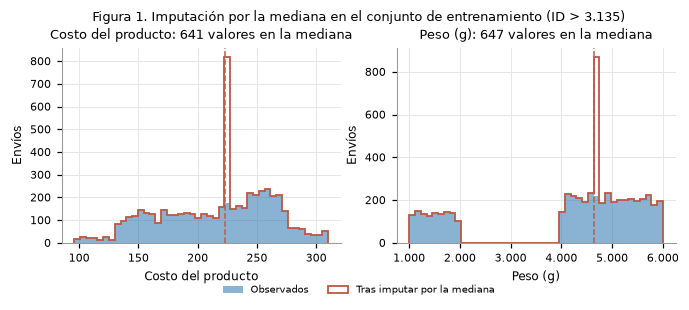

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.3))
etiquetas = {"Cost_of_the_Product": "Costo del producto", "Weight_in_gms": "Peso (g)"}
for ax, v in zip(axes, VARS_FALTANTES):
    obs = entrenamiento.loc[entrenamiento[v + "_faltante"].eq(0), v]
    bins = np.linspace(obs.min(), obs.max(), 45)
    ax.hist(obs, bins=bins, color=C_A_TIEMPO, alpha=0.55, label="Observados")
    ax.hist(entrenamiento[v], bins=bins, histtype="step", color=C_FUERA, lw=1.2, label="Tras imputar por la mediana")
    ax.axvline(medianas[v], color=C_FUERA, ls="--", lw=1)
    ax.set_xlabel(etiquetas[v]); ax.set_ylabel("Envíos")
    ax.set_title(f"{etiquetas[v]}: {int(entrenamiento[v + '_faltante'].sum()):,} valores en la mediana")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Figura 1. Imputación por la mediana en el conjunto de entrenamiento (ID > 3.135)", fontsize=8.5, y=1.03)
guardar_figura(fig, "f2_fig01_imputacion_mediana")
plt.show()

### 1.6 Estandarización y codificación

La importancia del producto se codifica como un indicador binario (alta = 1, resto = 0), porque S1 y S2 encontraron la diferencia entre alta y el resto, no entre baja y media. El costo y el peso se estandarizan con la media y la desviación estándar **del entrenamiento**, de modo que sus odds ratios se leen por desviación estándar y son comparables entre sí. El indicador binario no se estandariza, para que su odds ratio compare directamente importancia alta con el resto.

In [11]:
NUMERICAS = ["Cost_of_the_Product", "Weight_in_gms"]
PREDICTORES = ["Importancia_alta"] + NUMERICAS
media_ent, de_ent = entrenamiento[NUMERICAS].mean(), entrenamiento[NUMERICAS].std()


def matriz_diseno(d):
    x = d[PREDICTORES].astype(float).copy()
    x[NUMERICAS] = (x[NUMERICAS] - media_ent) / de_ent
    return sm.add_constant(x)


X_ent, X_pru = matriz_diseno(entrenamiento), matriz_diseno(prueba)
y_ent, y_pru = entrenamiento[OBJETIVO].to_numpy(), prueba[OBJETIVO].to_numpy()
escala = pd.DataFrame({"media_entrenamiento": media_ent, "de_entrenamiento": de_ent})
display(escala)
print("Prueba estandarizada con parámetros de entrenamiento: medias =",
      {k: round(v, 3) for k, v in X_pru[NUMERICAS].mean().items()})

,media_entrenamiento,de_entrenamiento
Cost_of_the_Product,216.086119,45.263332
Weight_in_gms,4176.274891,1502.762633


Prueba estandarizada con parámetros de entrenamiento: medias = {'Cost_of_the_Product': 0.033, 'Weight_in_gms': 0.042}


## 2. Modelo de regresión logística

### 2.1 Selección de variables justificada en S1 y S2

Se revisan todas las variables candidatas con su evidencia en S1 (conjunto completo) y en S2 (ID > 3.135). El criterio es el de S2: una variable entra si tiene evidencia **dentro de ID > 3.135** y si se conoce antes del despacho. La evidencia del conjunto completo no basta, porque S2 mostró que depende del bloque inicial.

In [12]:
t06 = s1("tab06_tasa_por_categoria")
t15 = s1("tab15_pruebas_complementarias")
rango = lambda var: t06.loc[t06["variable"].eq(var), "tasa"].agg(["min", "max"])
z_comp = t15.loc[t15["prueba"].str.startswith("z") & t15["conjunto"].eq("Completo")].iloc[0]
z_sub_s1 = t15.loc[t15["prueba"].str.startswith("z") & t15["conjunto"].eq("ID > 3135")].iloc[0]
chi_modo = t15.loc[t15["prueba"].str.startswith("χ² medio")].iloc[0]
r = lambda v: f"ρ = {es(t05.loc[v, 'spearman'], 3)}"
f3 = lambda x: es(x, 4) if abs(x) < 0.0005 else es(x, 3)
rs = lambda v: f"ρ = {f3(rho_s.loc[v, 'rho'])} [{f3(rho_s.loc[v, 'ic_inf'])}; {f3(rho_s.loc[v, 'ic_sup'])}]"
seleccion = guardar_tabla(pd.DataFrame([
    {"variable": "Importancia alta", "evidencia_s1": f"z: +{es(z_comp['diferencia_pp'], 2)} pp, p = {es(z_comp['p_valor'], 4)}",
     "evidencia_s2_id_gt_3135": f"+{es(z_sub_s1['diferencia_pp'], 2)} pp, p perm. = {es(z_sub['p_perm_final'], 4)}; señal exploratoria (Holm {es(z_sub['p_holm_subconjunto'], 3)})",
     "decision": "Incluir", "motivo": "Única señal que conserva dirección y magnitud en ambos conjuntos"},
    {"variable": "Costo", "evidencia_s1": r("Cost_of_the_Product"), "evidencia_s2_id_gt_3135": rs("Costo") + "; parámetro robusto",
     "decision": "Incluir", "motivo": "IC excluye el 0 en ID > 3.135 (signo opuesto al completo); conocido antes del despacho"},
    {"variable": "Peso", "evidencia_s1": r("Weight_in_gms") + "; Welch p < 0,0001", "evidencia_s2_id_gt_3135": rs("Peso") + "; atenuada",
     "decision": "Incluir", "motivo": "Conserva el signo de S1 y su IC excluye el 0 por poco; conocido antes del despacho"},
    {"variable": "Descuento", "evidencia_s1": r("Discount_offered") + "; > 10 ⇒ 100 % retraso",
     "evidencia_s2_id_gt_3135": rs("Descuento"), "decision": "Excluir", "motivo": "Asociación nula sin el bloque"},
    {"variable": "Compras previas", "evidencia_s1": r("Prior_purchases"), "evidencia_s2_id_gt_3135": rs("Compras previas"),
     "decision": "Excluir", "motivo": "Asociación nula sin el bloque"},
    {"variable": "Llamadas", "evidencia_s1": r("Customer_care_calls") + "; paradoja de Simpson",
     "evidencia_s2_id_gt_3135": rs("Llamadas"), "decision": "Excluir", "motivo": "Posible registro posterior al despacho (fuga)"},
    {"variable": "Calificación", "evidencia_s1": r("Customer_rating"), "evidencia_s2_id_gt_3135": "No evaluada (S1 sin señal)",
     "decision": "Excluir", "motivo": "Posterior a la entrega (fuga) y sin señal en S1"},
    {"variable": "Medio de transporte", "evidencia_s1": f"χ² p = {es(chi_modo['p_valor'], 2)}; tasas {es(rango('Mode_of_Shipment')['min'], 1)}-{es(rango('Mode_of_Shipment')['max'], 1)} %",
     "evidencia_s2_id_gt_3135": "No evaluada (S1 sin señal)", "decision": "Excluir", "motivo": "Sin asociación en S1"},
    {"variable": "Bloque de almacén", "evidencia_s1": f"Tasas {es(rango('Warehouse_block')['min'], 1)}-{es(rango('Warehouse_block')['max'], 1)} %",
     "evidencia_s2_id_gt_3135": "No evaluada (S1 sin señal)", "decision": "Excluir", "motivo": "Sin asociación en S1"},
    {"variable": "Género", "evidencia_s1": f"Tasas {es(rango('Gender')['min'], 1)}-{es(rango('Gender')['max'], 1)} %",
     "evidencia_s2_id_gt_3135": "No evaluada (S1 sin señal)", "decision": "Excluir", "motivo": "Sin asociación en S1"},
]), "f2_tab06_seleccion_variables")
display(seleccion)
print("Variables del modelo:", ", ".join(seleccion.loc[seleccion["decision"].eq("Incluir"), "variable"]))

,variable,evidencia_s1,evidencia_s2_id_gt_3135,decision,motivo
0,Importancia alta,"z: +5,81 pp, p = 0,0005","+4,31 pp, p perm. = 0,0357; señal exploratoria...",Incluir,Única señal que conserva dirección y magnitud ...
1,Costo,"ρ = −0,072","ρ = 0,034 [0,012; 0,056]; parámetro robusto",Incluir,IC excluye el 0 en ID > 3.135 (signo opuesto a...
2,Peso,"ρ = −0,266; Welch p < 0,0001","ρ = −0,023 [−0,045; −0,0003]; atenuada",Incluir,Conserva el signo de S1 y su IC excluye el 0 p...
3,Descuento,"ρ = 0,335; > 10 ⇒ 100 % retraso","ρ = −0,010 [−0,032; 0,012]",Excluir,Asociación nula sin el bloque
4,Compras previas,"ρ = −0,075","ρ = 0,007 [−0,015; 0,030]",Excluir,Asociación nula sin el bloque
5,Llamadas,"ρ = −0,064; paradoja de Simpson","ρ = 0,026 [0,004; 0,048]",Excluir,Posible registro posterior al despacho (fuga)
6,Calificación,"ρ = 0,013",No evaluada (S1 sin señal),Excluir,Posterior a la entrega (fuga) y sin señal en S1
7,Medio de transporte,"χ² p = 0,69; tasas 58,8-60,2 %",No evaluada (S1 sin señal),Excluir,Sin asociación en S1
8,Bloque de almacén,"Tasas 58,6-60,2 %",No evaluada (S1 sin señal),Excluir,Sin asociación en S1
9,Género,"Tasas 59,4-59,9 %",No evaluada (S1 sin señal),Excluir,Sin asociación en S1


Variables del modelo: Importancia alta, Costo, Peso


### 2.2 Ajuste del modelo

Se ajusta por máxima verosimilitud con `statsmodels`, que entrega errores estándar, valores p e intervalos de Wald. No se necesita la corrección de Firth: en ID > 3.135 el descuento, que separaba las clases en el conjunto completo, no forma parte del modelo, y las variables incluidas no separan las clases.

In [13]:
modelo = sm.Logit(y_ent, X_ent).fit(disp=0)
assert modelo.mle_retvals["converged"]
print(modelo.summary2(title="Regresión logística · entrenamiento ID > 3.135"))

          Regresión logística · entrenamiento ID > 3.135
Model:               Logit             Method:            MLE      
Dependent Variable:  y                 Pseudo R-squared:  0.002    
Date:                2026-10-25 21:39  AIC:               7535.6702
No. Observations:    5504              BIC:               7562.1231
Df Model:            3                 Log-Likelihood:    -3763.8  
Df Residuals:        5500              LL-Null:           -3769.7  
Converged:           1.0000            LLR p-value:       0.0085434
No. Iterations:      4.0000            Scale:             1.0000   
-------------------------------------------------------------------
                     Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
-------------------------------------------------------------------
const               -0.2735   0.0284 -9.6162 0.0000 -0.3293 -0.2178
Importancia_alta     0.1838   0.0995  1.8469 0.0648 -0.0112  0.3788
Cost_of_the_Product  0.0601   0.0298  2.0134 0.0441  0.0016

### 2.3 Coeficientes, odds ratios y significancia

El odds ratio (OR) es el exponencial del coeficiente: el factor por el que se multiplican las odds de retraso cuando el predictor sube una unidad (una desviación estándar para costo y peso; de resto a importancia alta para el indicador), con lo demás constante. Como se contrastan tres predictores, se agrega la corrección de Holm que S2 recomendó para evaluar varios predictores en el subconjunto.

In [14]:
ic = modelo.conf_int()
coef = pd.DataFrame({
    "coeficiente": modelo.params, "ee": modelo.bse, "z": modelo.tvalues, "p": modelo.pvalues,
    "OR": np.exp(modelo.params), "OR_inf": np.exp(ic[0]), "OR_sup": np.exp(ic[1]),
})
coef.loc[PREDICTORES, "p_holm"] = multipletests(coef.loc[PREDICTORES, "p"], method="holm")[1]
coef.index.name = "termino"
guardar_tabla(coef.reset_index(), "f2_tab07_coeficientes")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(coef)

,coeficiente,ee,z,p,OR,OR_inf,OR_sup,p_holm
termino,,,,,,,,
const,-0.2735,0.0284,-9.6162,0.0000,0.7607,0.7195,0.8043,NaN
Importancia_alta,0.1838,0.0995,1.8469,0.0648,1.2017,0.9888,1.4605,0.1322
Cost_of_the_Product,0.0601,0.0298,2.0134,0.0441,1.0619,1.0016,1.1259,0.1322
Weight_in_gms,-0.0379,0.0299,-1.2667,0.2053,0.9629,0.9081,1.0209,0.2053


In [15]:
c = coef
de_costo, de_peso = de_ent["Cost_of_the_Product"], de_ent["Weight_in_gms"]
base_odds = np.exp(c.loc["const", "coeficiente"])
display(Markdown(
    f"**Interpretación.** "
    f"**Importancia alta:** OR = {es(c.loc['Importancia_alta', 'OR'], 2)} "
    f"[{es(c.loc['Importancia_alta', 'OR_inf'], 2)}; {es(c.loc['Importancia_alta', 'OR_sup'], 2)}]: los envíos de importancia alta "
    f"tienen odds de retraso un {es(100 * (c.loc['Importancia_alta', 'OR'] - 1), 0)} % mayores que el resto, la misma dirección de S1 y S2; "
    f"el IC incluye el 1 y p = {es(c.loc['Importancia_alta', 'p'], 3)}; igual que en S2 la señal no se confirma. "
    f"**Costo:** OR = {es(c.loc['Cost_of_the_Product', 'OR'], 3)} por desviación estándar ({es(de_costo, 1)} unidades monetarias), "
    f"p = {es(c.loc['Cost_of_the_Product', 'p'], 3)}: los productos más caros se retrasan algo más dentro de ID > 3.135, el signo que S2 encontró en el subconjunto "
    f"y opuesto al del conjunto completo. "
    f"**Peso:** OR = {es(c.loc['Weight_in_gms', 'OR'], 3)} por desviación estándar ({es(de_peso, 0)} g), p = {es(c.loc['Weight_in_gms', 'p'], 3)}: "
    f"conserva el signo de S1, con una magnitud mínima. "
    f"**Holm:** ningún predictor es significativo tras corregir por multiplicidad (menor p ajustado = {es(c.loc[PREDICTORES, 'p_holm'].min(), 3)}). "
    f"**Intercepto:** odds base = {es(base_odds, 3)}, que corresponde a una probabilidad de {pct(base_odds / (1 + base_odds))} "
    f"para un producto de importancia no alta con costo y peso promedio, cercana a la tasa de {pct(y_ent.mean())} del entrenamiento. "
    f"Todos los efectos son pequeños: el modelo describe diferencias de pocos puntos porcentuales en la probabilidad de retraso."
))

**Interpretación.** **Importancia alta:** OR = 1,20 [0,99; 1,46]: los envíos de importancia alta tienen odds de retraso un 20 % mayores que el resto, la misma dirección de S1 y S2; el IC incluye el 1 y p = 0,065; igual que en S2 la señal no se confirma. **Costo:** OR = 1,062 por desviación estándar (45,3 unidades monetarias), p = 0,044: los productos más caros se retrasan algo más dentro de ID > 3.135, el signo que S2 encontró en el subconjunto y opuesto al del conjunto completo. **Peso:** OR = 0,963 por desviación estándar (1.503 g), p = 0,205: conserva el signo de S1, con una magnitud mínima. **Holm:** ningún predictor es significativo tras corregir por multiplicidad (menor p ajustado = 0,132). **Intercepto:** odds base = 0,761, que corresponde a una probabilidad de 43,2 % para un producto de importancia no alta con costo y peso promedio, cercana a la tasa de 43,6 % del entrenamiento. Todos los efectos son pequeños: el modelo describe diferencias de pocos puntos porcentuales en la probabilidad de retraso.

### 2.4 Diagnóstico de multicolinealidad (VIF)

El factor de inflación de varianza mide cuánto crece la varianza de cada coeficiente por la correlación con los demás predictores. Un VIF sobre 5 sería señal de alerta.

In [16]:
vif = guardar_tabla(pd.DataFrame({
    "predictor": PREDICTORES,
    "VIF": [variance_inflation_factor(X_ent.to_numpy(), i) for i in range(1, X_ent.shape[1])],
}), "f2_tab08_vif")
display(vif)
print(f"Correlación costo-peso en entrenamiento: r = {entrenamiento['Cost_of_the_Product'].corr(entrenamiento['Weight_in_gms']):.3f}")
assert vif["VIF"].max() < 5

,predictor,VIF
0,Importancia_alta,1.016296
1,Cost_of_the_Product,1.196417
2,Weight_in_gms,1.212911


Correlación costo-peso en entrenamiento: r = -0.405


Todos los VIF están muy cerca de 1: los tres predictores aportan información prácticamente independiente y no hay multicolinealidad que documentar. La correlación negativa moderada entre costo y peso dentro de ID > 3.135 no alcanza a inflar las varianzas.

## 3. Evaluación del desempeño predictivo

### 3.1 Predicciones y matriz de confusión

Las probabilidades se calculan sobre el conjunto de prueba, que no participó en el ajuste, la imputación ni la estandarización. Se comparan dos umbrales de clasificación:

- **0,5**, el umbral por defecto.
- **La tasa de retraso del entrenamiento** (43,6 %), elegida sin mirar el conjunto de prueba. Clasifica como retraso a los envíos cuya probabilidad supera la tasa base, y es el punto de operación al que se acerca la ponderación de clases que se usará en S3.

La referencia es la regla trivial de la clase mayoritaria (todo «a tiempo»), que S2 recomendó usar como línea base.

Probabilidades predichas en prueba: mínimo 0.385, mediana 0.433, máximo 0.520


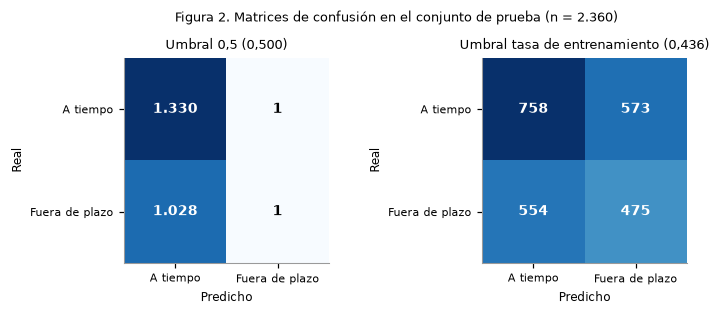

In [17]:
p_pru = modelo.predict(X_pru).to_numpy()
p_ent = modelo.predict(X_ent).to_numpy()
UMBRALES = {"0,5": 0.5, "Tasa de entrenamiento": float(y_ent.mean())}
print(f"Probabilidades predichas en prueba: mínimo {p_pru.min():.3f}, mediana {np.median(p_pru):.3f}, máximo {p_pru.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.5), gridspec_kw={"wspace": 0.75})
matrices = {}
for ax, (nombre, u) in zip(axes, UMBRALES.items()):
    cm = confusion_matrix(y_pru, (p_pru >= u).astype(int), labels=[0, 1])
    matrices[nombre] = cm
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}".replace(",", "."), ha="center", va="center",
                color="white" if v > 0.55 * cm.max() else "black", fontsize=9, fontweight="bold")
    ax.set_xticks([0, 1], ["A tiempo", "Fuera de plazo"]); ax.set_yticks([0, 1], ["A tiempo", "Fuera de plazo"])
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.grid(False)
    ax.set_title(f"Umbral {nombre.lower()} ({es(u, 3)})")
fig.suptitle("Figura 2. Matrices de confusión en el conjunto de prueba (n = 2.360)", fontsize=8.5, y=1.04)
guardar_figura(fig, "f2_fig02_matrices_confusion")
plt.show()

### 3.2 Métricas de desempeño

Se informan las métricas de la clase positiva, retraso (1). **Accuracy:** fracción de envíos bien clasificados. **Precision:** de los envíos marcados como retraso, cuántos lo fueron. **Recall** (sensibilidad): de los retrasos reales, cuántos detecta el modelo. **F1:** media armónica de precision y recall.

In [18]:
filas = [{"clasificador": "Línea base: todo «a tiempo»", "umbral": np.nan, "accuracy": 1 - y_pru.mean(),
          "precision": np.nan, "recall": 0.0, "f1": 0.0, "especificidad": 1.0}]
for nombre, u in UMBRALES.items():
    yh = (p_pru >= u).astype(int)
    tn, fp, fn, tp = matrices[nombre].ravel()
    filas.append({"clasificador": f"Logística, umbral {nombre.lower()}", "umbral": u,
                  "accuracy": accuracy_score(y_pru, yh), "precision": precision_score(y_pru, yh, zero_division=0),
                  "recall": recall_score(y_pru, yh), "f1": f1_score(y_pru, yh), "especificidad": tn / (tn + fp)})
metricas = guardar_tabla(pd.DataFrame(filas), "f2_tab09_metricas")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(metricas)

,clasificador,umbral,accuracy,precision,recall,f1,especificidad
0,Línea base: todo «a tiempo»,NaN,0.5640,NaN,0.0000,0.0000,1.0000
1,"Logística, umbral 0,5",0.5000,0.5640,0.5000,0.0010,0.0019,0.9992
2,"Logística, umbral tasa de entrenamiento",0.4359,0.5225,0.4532,0.4616,0.4574,0.5695


In [19]:
m05, mtb, base = metricas.iloc[1], metricas.iloc[2], metricas.iloc[0]
cm05 = matrices["0,5"]
display(Markdown(
    f"**Lectura en el contexto del problema.** Con umbral 0,5 el modelo marca solo {int(cm05[:, 1].sum())} de 2.360 envíos como retraso "
    f"y detecta {int(cm05[1, 1])} de {es(cm05[1].sum(), 0)} retrasos reales (recall = {es(m05['recall'], 3)}). "
    f"Su accuracy de {pct(m05['accuracy'])} es idéntica a la de la regla trivial «todo a tiempo» ({pct(base['accuracy'])}): "
    f"como las probabilidades predichas van de {es(p_pru.min(), 3)} a {es(p_pru.max(), 3)}, casi ninguna supera 0,5, y el modelo se comporta como la clase mayoritaria. "
    f"Para una operación logística que quiere anticipar retrasos, ese clasificador no sirve. "
    f"Con el umbral en la tasa de entrenamiento el recall sube a {es(mtb['recall'], 3)} y la precision es {es(mtb['precision'], 3)}, "
    f"apenas sobre la tasa base de {es(y_pru.mean(), 3)}; pero la accuracy cae a {pct(mtb['accuracy'])}, por debajo de la línea base. "
    f"Mover el umbral solo intercambia aciertos entre clases: no hay un punto de operación que mejore a la vez ambas, "
    f"la señal de un modelo que casi no discrimina."
))

**Lectura en el contexto del problema.** Con umbral 0,5 el modelo marca solo 2 de 2.360 envíos como retraso y detecta 1 de 1.029 retrasos reales (recall = 0,001). Su accuracy de 56,4 % es idéntica a la de la regla trivial «todo a tiempo» (56,4 %): como las probabilidades predichas van de 0,385 a 0,520, casi ninguna supera 0,5, y el modelo se comporta como la clase mayoritaria. Para una operación logística que quiere anticipar retrasos, ese clasificador no sirve. Con el umbral en la tasa de entrenamiento el recall sube a 0,462 y la precision es 0,453, apenas sobre la tasa base de 0,436; pero la accuracy cae a 52,2 %, por debajo de la línea base. Mover el umbral solo intercambia aciertos entre clases: no hay un punto de operación que mejore a la vez ambas, la señal de un modelo que casi no discrimina.

### 3.3 Curva ROC y AUC

El AUC es la probabilidad de que el modelo asigne mayor probabilidad de retraso a un envío fuera de plazo que a uno a tiempo, elegidos al azar. No depende del umbral. Escala de referencia del curso: 0,5 no mejor que el azar; 0,6-0,7 pobre; 0,7-0,8 aceptable; 0,8-0,9 bueno; > 0,9 excelente.

Además del valor puntual se cuantifica su incertidumbre, como en S2:

- **IC bootstrap percentil** del AUC: 10.000 remuestras del conjunto de prueba.
- **Prueba de permutación** (Ojala y Garriga, 2010): se permutan 10.000 veces las etiquetas del conjunto de prueba manteniendo las probabilidades. Así se obtiene la distribución del AUC de un modelo sin relación con el objetivo, y el valor p unilateral indica si el AUC observado supera lo esperable por azar.

In [20]:
def auc_por_rangos(rangos, y):
    # AUC de Mann-Whitney a partir de los rangos de las probabilidades (vectorizado sobre filas de y).
    n1 = y.sum(axis=-1)
    n0 = y.shape[-1] - n1
    return ((rangos * y).sum(axis=-1) - n1 * (n1 + 1) / 2) / (n1 * n0)


auc_pru = roc_auc_score(y_pru, p_pru)
auc_ent = roc_auc_score(y_ent, p_ent)
rangos = stats.rankdata(p_pru)
assert np.isclose(auc_por_rangos(rangos, y_pru), auc_pru)

rng = np.random.default_rng(SEED)
perm = np.empty(B_PERM)
for ini in range(0, B_PERM, 500):
    fin = min(ini + 500, B_PERM)
    etiquetas = np.array([rng.permutation(y_pru) for _ in range(fin - ini)])
    perm[ini:fin] = auc_por_rangos(rangos, etiquetas)
p_perm = (np.sum(perm >= auc_pru) + 1) / (B_PERM + 1)

boot = np.empty(B_BOOT)
n_pru = len(y_pru)
for b in range(B_BOOT):
    idx = rng.integers(0, n_pru, n_pru)
    boot[b] = roc_auc_score(y_pru[idx], p_pru[idx])
ic_auc = np.percentile(boot, [2.5, 97.5])

auc_tabla = guardar_tabla(pd.DataFrame([{
    "auc_entrenamiento": auc_ent, "auc_prueba": auc_pru, "ic_boot_inf": ic_auc[0], "ic_boot_sup": ic_auc[1],
    "ee_boot": boot.std(ddof=1), "media_nula_perm": perm.mean(), "p95_nula_perm": np.percentile(perm, 95),
    "p_permutacion": p_perm, "ee_mc_p": np.sqrt(p_perm * (1 - p_perm) / B_PERM), "B_boot": B_BOOT, "B_perm": B_PERM,
}]), "f2_tab10_auc_inferencia")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(auc_tabla)

,auc_entrenamiento,auc_prueba,ic_boot_inf,ic_boot_sup,ee_boot,media_nula_perm,p95_nula_perm,p_permutacion,ee_mc_p,B_boot,B_perm
0,0.5278,0.5147,0.4915,0.5384,0.0121,0.5000,0.5197,0.1074,0.0031,10000,10000


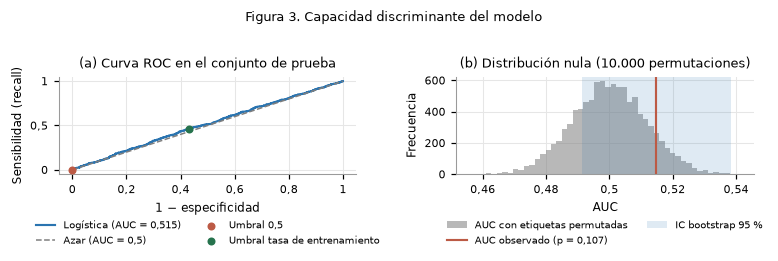

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
fpr, tpr, _ = roc_curve(y_pru, p_pru)
ax = axes[0]
ax.plot(fpr, tpr, color=C_A_TIEMPO, lw=1.4, label=f"Logística (AUC = {es(auc_pru, 3)})")
ax.plot([0, 1], [0, 1], color=C_GRIS, ls="--", lw=1, label="Azar (AUC = 0,5)")
for nombre, u in UMBRALES.items():
    tn, fp, fn, tp = matrices[nombre].ravel()
    ax.scatter(fp / (fp + tn), tp / (tp + fn), s=18, zorder=3, color=C_FUERA if u == 0.5 else "#26734D",
               label=f"Umbral {nombre.lower()}")
ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad (recall)")
ax.set_title("(a) Curva ROC en el conjunto de prueba"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=2)
ax = axes[1]
ax.hist(perm, bins=50, color=C_GRIS, alpha=0.55, label="AUC con etiquetas permutadas")
ax.axvline(auc_pru, color=C_FUERA, lw=1.4, label=f"AUC observado (p = {es(p_perm, 3)})")
ax.axvspan(*ic_auc, color=C_A_TIEMPO, alpha=0.15, lw=0, label="IC bootstrap 95 %")
ax.set_xlabel("AUC"); ax.set_ylabel("Frecuencia"); ax.set_title(f"(b) Distribución nula ({B_PERM:,} permutaciones)".replace(",", "."))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=2)
fig.suptitle("Figura 3. Capacidad discriminante del modelo", fontsize=8.5, y=1.02)
fig.tight_layout()
guardar_figura(fig, "f2_fig03_roc_auc")
plt.show()

In [22]:
a = auc_tabla.iloc[0]
display(Markdown(
    f"**Interpretación.** El AUC en prueba es {es(a['auc_prueba'], 3)} [IC bootstrap 95 %: {es(a['ic_boot_inf'], 3)}; {es(a['ic_boot_sup'], 3)}]: "
    f"en la escala de referencia, **no mejor que el azar**. El intervalo incluye 0,5, y la prueba de permutación lo confirma: "
    f"un modelo sin ninguna relación con el objetivo alcanza un AUC igual o mayor en el {pct(a['p_permutacion'])} de las permutaciones "
    f"(p = {es(a['p_permutacion'], 3)} ± {es(a['ee_mc_p'], 3)}). "
    f"El AUC de entrenamiento ({es(a['auc_entrenamiento'], 3)}) es apenas mayor: no hay sobreajuste, porque no hay señal que sobreajustar. "
    f"El resultado es coherente con S2: sin el bloque inicial, las asociaciones de S1 desaparecen o quedan en magnitudes mínimas, "
    f"y la potencia para detectar la diferencia de la importancia alta era de 49 %."
))

**Interpretación.** El AUC en prueba es 0,515 [IC bootstrap 95 %: 0,491; 0,538]: en la escala de referencia, **no mejor que el azar**. El intervalo incluye 0,5, y la prueba de permutación lo confirma: un modelo sin ninguna relación con el objetivo alcanza un AUC igual o mayor en el 10,7 % de las permutaciones (p = 0,107 ± 0,003). El AUC de entrenamiento (0,528) es apenas mayor: no hay sobreajuste, porque no hay señal que sobreajustar. El resultado es coherente con S2: sin el bloque inicial, las asociaciones de S1 desaparecen o quedan en magnitudes mínimas, y la potencia para detectar la diferencia de la importancia alta era de 49 %.

## 4. Síntesis y reflexión

**Cómo se integraron S1 y S2.** S1 aportó las correlaciones con el retraso, la ausencia de faltantes, los atípicos del descuento y el hallazgo central: el bloque ID ≤ 3.135 tiene 100 % de retrasos y descuentos mayores a 10 que separan las clases. S2 aportó la regla para decidir qué usar. Ninguna correlación resultó estable, el costo medio es el único parámetro robusto y la importancia alta es la única señal que conserva dirección y magnitud en ambos conjuntos. De ahí salen todas las decisiones de esta formativa:

- **Datos:** modelar en ID > 3.135, donde no hay separación y no se necesita Firth.
- **Partición:** aleatoria y estratificada 70/30, válida porque el bootstrap por bloques no encontró estructura por orden (razón de EE de 0,92 a 1,01).
- **Variables:** importancia alta, costo y peso, elegidas por su evidencia dentro del subconjunto. Se excluyeron el descuento y las compras previas, cuya asociación es nula sin el bloque, y las llamadas y la calificación, por posible fuga.
- **Faltantes:** imputación por la mediana, el resumen que S2 recomendó para el peso bimodal.

**Desempeño.** El modelo no discrimina: AUC = 0,515 [0,491; 0,538], con p = 0,107 en la prueba de permutación. Ningún predictor sobrevive a Holm. La importancia alta conserva la dirección de S1 (OR = 1,20) sin confirmarse. Con umbral 0,5 el recall es 0,001 y la accuracy (56,4 %) iguala a la de la regla trivial. Bajando el umbral a la tasa base, el recall sube a 0,462 a costa de una accuracy de 52,2 %. Es un resultado negativo, pero informativo y coherente con el proyecto: lo que en S1 parecía predecir el retraso era, en gran medida, la huella del bloque inicial.

**Mejoras para S3.**

1. **Imputación:** reemplazar la mediana por regresión lineal múltiple y comparar eliminación, mediana y regresión, incluido el error contra los valores verdaderos. La mediana deja 647 valores de peso en un solo punto y reduce su desviación estándar un 5,5 %.
2. **Modelos:** ajustar tres (variables validadas, stepwise por AIC y reducido), con validación cruzada y curvas ROC comparadas.
3. **Clasificación:** incorporar la ponderación de clases para fijar un punto de operación con recall útil.
4. **Bootstrap:** aplicar 10.000 remuestras a los coeficientes del mejor modelo e identificar los odds ratios inestables.
5. **Diagnóstico:** ampliarlo con linealidad en el logit (Box-Tidwell) y observaciones influyentes (distancia de Cook).
6. **Contraste con el bloque:** repetir el modelo en el conjunto completo con un indicador del bloque, para cuantificar cuánto del AUC aparente proviene de él.

### Referencias

- Ojala, M. y Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research, 11*, 1833-1863.
- Seabold, S. y Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92-96.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

### Control de consistencia

La síntesis está escrita en Markdown con cifras fijas. Esta celda verifica que cada cifra citada coincida con el resultado calculado en este notebook, de modo que el texto no pueda quedar desactualizado respecto del código.

In [23]:
redondeo = lambda x, d: round(float(x), d)
citas = {
    "AUC prueba 0,515": (redondeo(auc_pru, 3), 0.515),
    "IC inferior 0,491": (redondeo(ic_auc[0], 3), 0.491),
    "IC superior 0,538": (redondeo(ic_auc[1], 3), 0.538),
    "p permutación 0,107": (redondeo(p_perm, 3), 0.107),
    "OR importancia alta 1,20": (redondeo(coef.loc["Importancia_alta", "OR"], 2), 1.20),
    "recall umbral 0,5 = 0,001": (redondeo(m05["recall"], 3), 0.001),
    "accuracy umbral 0,5 = 56,4 %": (redondeo(100 * m05["accuracy"], 1), 56.4),
    "accuracy línea base = 56,4 %": (redondeo(100 * base["accuracy"], 1), 56.4),
    "recall umbral tasa = 0,462": (redondeo(mtb["recall"], 3), 0.462),
    "accuracy umbral tasa = 52,2 %": (redondeo(100 * mtb["accuracy"], 1), 52.2),
    "razón EE bloques mínima 0,92": (redondeo(razon_sub.min(), 2), 0.92),
    "razón EE bloques máxima 1,01": (redondeo(razon_sub.max(), 2), 1.01),
    "peso imputado en entrenamiento 647": (int(imputacion.loc[(imputacion.variable == "Weight_in_gms") & (imputacion.conjunto == "Entrenamiento"), "imputados"].iloc[0]), 647),
    "reducción DE peso 5,5 %": (redondeo(-imputacion.loc[(imputacion.variable == "Weight_in_gms") & (imputacion.conjunto == "Entrenamiento"), "cambio_de_pct"].iloc[0], 1), 5.5),
    "ningún predictor sobrevive a Holm": (bool(coef.loc[PREDICTORES, "p_holm"].min() > 0.05), True),
}
fallas = {k: v for k, v in citas.items() if v[0] != v[1]}
for k, (calc, texto) in citas.items():
    print(f"{'OK ' if calc == texto else 'ERROR'} {k}: calculado {calc}")
assert not fallas, f"Cifras de la síntesis desactualizadas: {fallas}"
print(f"\nTablas exportadas: {len(list(DIR_TABLAS.glob('f2_*.csv')))} · figuras: {len(list(DIR_FIGURAS.glob('f2_*.png')))}")

OK  AUC prueba 0,515: calculado 0.515
OK  IC inferior 0,491: calculado 0.491
OK  IC superior 0,538: calculado 0.538
OK  p permutación 0,107: calculado 0.107
OK  OR importancia alta 1,20: calculado 1.2
OK  recall umbral 0,5 = 0,001: calculado 0.001
OK  accuracy umbral 0,5 = 56,4 %: calculado 56.4
OK  accuracy línea base = 56,4 %: calculado 56.4
OK  recall umbral tasa = 0,462: calculado 0.462
OK  accuracy umbral tasa = 52,2 %: calculado 52.2
OK  razón EE bloques mínima 0,92: calculado 0.92
OK  razón EE bloques máxima 1,01: calculado 1.01
OK  peso imputado en entrenamiento 647: calculado 647
OK  reducción DE peso 5,5 %: calculado 5.5
OK  ningún predictor sobrevive a Holm: calculado True

Tablas exportadas: 10 · figuras: 3
